# 04. 결과 분석 & 모델 해석 (Mission 4 · 5)

| 구분 | 내용 |
|---|---|
| Mission 4 | Before(E0) vs After(최종 모델) 비교, 혼동행렬, 임계값에 따른 민감도·특이도, 오답(FN·FP) 이미지 분석 |
| Mission 5 | Grad-CAM 해석 2가지 이상, 결과 데이터 정의, Risk Level 정의 |

**사용 모델**
- Before: `baseline_simplecnn.pth` (E0, SimpleCNN 128)
- After: `MODEL_NAME` (셀 3에서 지정, 기본값 E1b)

**규칙 준수**
- 임계값·Risk Level 기준은 **검증셋으로만** 정함 (테스트셋은 예측과 관찰에만 사용)
- 학습은 하지 않음 → 03_Experiments에서 저장한 가중치를 불러와 분석만 함

In [1]:
# Setup & reproducibility


import os
import random
import numpy as np
import torch

SEED = 42

def seed_everything(seed):
    # 파이썬 · numpy · 파이토치(CPU/GPU) 무작위 고정
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # GPU 연산을 매번 같은 방식으로
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


# → 무작위 요소를 SEED=42로 고정하고 사용할 장치(GPU)를 확인하겠다

device: cuda


In [2]:
# Mount Drive & unzip data


from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/dacon_chest_xray"
ZIP_PATH = os.path.join(PROJECT_DIR, "data", "open.zip")
DATA_DIR = "/content/data"

# 압축이 이미 풀려 있으면 다시 풀지 않음 (세션이 이어지는 경우 시간 절약)
if not os.path.exists(os.path.join(DATA_DIR, "train")):
    !unzip -q -o "{ZIP_PATH}" -d "{DATA_DIR}"
print("data:", os.listdir(DATA_DIR))


# → 드라이브를 연결하고 데이터를 Colab 로컬(/content/data)에 풀겠다

Mounted at /content/drive
data: ['train', 'sample_submission.csv', 'test', 'test.csv', 'train.csv']


In [3]:
# Paths, fixed split & model choice


import pandas as pd

# MODEL_NAME : 분석할 최종 모델 이름 (03_Experiments에서 저장한 파일 이름과 같아야 함)
# E5가 E1b보다 리더보드가 높으면 "E5"로 바꿔서 실행
MODEL_NAME = "E1b"

tr_df = pd.read_csv(os.path.join(PROJECT_DIR, "data", "split_train.csv"))
val_df = pd.read_csv(os.path.join(PROJECT_DIR, "data", "split_valid.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
# 분석 결과(표·그림·결과 데이터)를 모아둘 폴더
OUT_DIR = os.path.join(PROJECT_DIR, "analysis")
os.makedirs(os.path.join(OUT_DIR, "gradcam"), exist_ok=True)

print(f"valid {len(val_df)} | test {len(test_df)} | model: {MODEL_NAME}")


# → 03_Experiments와 같은 고정 분할을 불러오고, 분석할 최종 모델 이름과 결과 저장 폴더를 정하겠다

valid 1044 | test 624 | model: E1b


In [4]:
# Transforms, datasets & models (same settings as training)


from PIL import Image
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# 최종 모델(ResNet18) 전처리 : 03_Experiments의 검증용 전처리와 동일 (Crop·증강 없음)
tf_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    # 흑백 1채널 → 3채널 복제 (사전학습 모델은 RGB 입력)
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
# Baseline(SimpleCNN) 전처리 : 02_Baseline과 동일
tf_base = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

class XrayDataset(Dataset):
    def __init__(self, df, root, tf, has_label=True):
        self.files = df["file_name"].tolist()
        self.labels = df["label"].astype(int).tolist() if has_label else None
        self.root, self.tf, self.has_label = root, tf, has_label
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.root, self.files[i])).convert("L")
        x = self.tf(img)
        return (x, self.labels[i]) if self.has_label else x

class SimpleCNN(nn.Module):
    # 02_Baseline의 공식 Baseline 구조 그대로 (저장된 가중치를 불러오려면 구조가 같아야 함)
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(32 * 32 * 32, 2))
    def forward(self, x):
        return self.fc(self.conv(x))

def load_resnet(name):
    # weights=None : 사전학습 가중치를 내려받지 않음 → 저장된 학습 결과로 바로 덮어쓰기 때문
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(torch.load(os.path.join(MODEL_DIR, f"{name}.pth"), map_location=device))
    return m.to(device).eval()

base_model = SimpleCNN().to(device)
base_model.load_state_dict(torch.load(os.path.join(MODEL_DIR, "baseline_simplecnn.pth"), map_location=device))
base_model.eval()
final_model = load_resnet(MODEL_NAME)

val_loader_base = DataLoader(XrayDataset(val_df, TRAIN_IMG_DIR, tf_base), batch_size=64, shuffle=False)
val_loader = DataLoader(XrayDataset(val_df, TRAIN_IMG_DIR, tf_resnet), batch_size=64, shuffle=False)
test_loader = DataLoader(XrayDataset(test_df, TEST_IMG_DIR, tf_resnet, has_label=False), batch_size=64, shuffle=False)
print("models loaded: baseline_simplecnn,", MODEL_NAME)


# → 학습 때와 똑같은 전처리로 Dataset을 만들고, 저장해 둔 Baseline·최종 모델 가중치를 불러오겠다

models loaded: baseline_simplecnn, E1b


## 📊 Mission 4-1. Before vs After 성능 비교

In [5]:
# Predict probabilities & compare metrics (E0 vs final)


from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, f1_score

@torch.no_grad()
def predict_probs(model, loader, has_label=True):
    # 폐렴(1)일 확률만 모아서 반환
    probs, labels = [], []
    for batch in loader:
        x = batch[0] if has_label else batch
        p = torch.softmax(model(x.to(device)), dim=1)[:, 1]
        probs.extend(p.cpu().numpy())
        if has_label:
            labels.extend(batch[1].numpy())
    return np.array(probs), (np.array(labels) if has_label else None)

def metrics_at(probs, labels, thr=0.5):
    # thr : 이 값 이상이면 폐렴(1)으로 판정
    preds = (probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    return {"thr": thr, "acc": accuracy_score(labels, preds), "auc": roc_auc_score(labels, probs),
            "sens": tp / (tp + fn), "spec": tn / (tn + fp), "f1": f1_score(labels, preds),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}

base_probs, val_labels = predict_probs(base_model, val_loader_base)
final_probs, _ = predict_probs(final_model, val_loader)
test_probs, _ = predict_probs(final_model, test_loader, has_label=False)

cmp = pd.DataFrame([{"model": "E0 Baseline", **metrics_at(base_probs, val_labels)},
                    {"model": MODEL_NAME, **metrics_at(final_probs, val_labels)}])
display(cmp.round(4))
print("test normal ratio:", round(1 - (test_probs >= 0.5).mean(), 3), "| test prob median:", round(float(np.median(test_probs)), 3))


# → 검증셋에서 Baseline과 최종 모델의 폐렴 확률을 구해 Accuracy·AUC·민감도·특이도·F1을 나란히 비교하고,
#   03_Experiments 기록과 같은 값이 나오는지(재현 확인) 보겠다

,model,thr,acc,auc,sens,spec,f1,tn,fp,fn,tp
0,E0 Baseline,0.5,0.9454,0.9832,0.9433,0.9515,0.9625,255,13,44,732
1,E1b,0.5,0.9799,0.9979,0.9768,0.9888,0.9863,265,3,18,758


test normal ratio: 0.386 | test prob median: 0.982


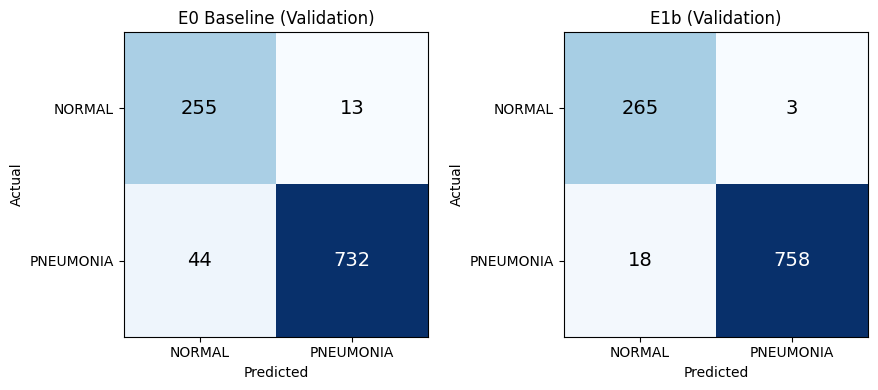

In [6]:
# Confusion matrices side by side


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, probs) in zip(axes, [("E0 Baseline", base_probs), (MODEL_NAME, final_probs)]):
    m = metrics_at(probs, val_labels)
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["NORMAL", "PNEUMONIA"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{name} (Validation)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_before_after.png"), dpi=150)
plt.show()


# → 두 모델의 혼동행렬을 나란히 그려, 어떤 종류의 실수(FN·FP)가 얼마나 줄었는지 한눈에 보고 그림으로 저장하겠다

## 📊 Mission 4-2. 임계값에 따른 민감도 · 특이도
- 임계값(threshold): 폐렴 확률이 이 값 **이상**이면 폐렴으로 판정
- 임계값을 **낮추면** 폐렴을 덜 놓침(민감도↑) 대신 정상을 폐렴으로 오진(특이도↓)
- ⚠️ 검증셋으로만 분석 (테스트 비율에 맞춰 임계값을 고르면 Data Leakage)

,thr,acc,sens,spec,fn,fp
0,0.05,0.9866,0.9897,0.9776,8,6
1,0.10,0.9866,0.9871,0.9851,10,4
2,0.20,0.9875,0.9871,0.9888,10,3
3,0.30,0.9837,0.9820,0.9888,14,3
4,0.40,0.9828,0.9807,0.9888,15,3
5,0.50,0.9799,0.9768,0.9888,18,3
6,0.60,0.9780,0.9742,0.9888,20,3
7,0.70,0.9761,0.9704,0.9925,23,2
8,0.80,0.9722,0.9652,0.9925,27,2
9,0.90,0.9646,0.9536,0.9963,36,1


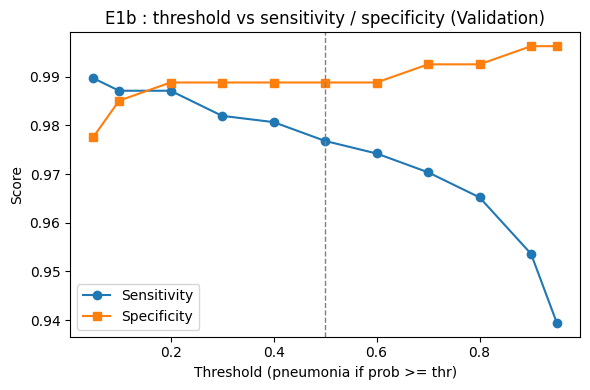

In [7]:
# Threshold sweep on validation


thr_list = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
sweep = pd.DataFrame([metrics_at(final_probs, val_labels, t) for t in thr_list])
display(sweep[["thr", "acc", "sens", "spec", "fn", "fp"]].round(4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sweep["thr"], sweep["sens"], marker="o", label="Sensitivity")
ax.plot(sweep["thr"], sweep["spec"], marker="s", label="Specificity")
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Threshold (pneumonia if prob >= thr)")
ax.set_ylabel("Score")
ax.set_title(f"{MODEL_NAME} : threshold vs sensitivity / specificity (Validation)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "threshold_sweep.png"), dpi=150)
plt.show()


# → 임계값을 0.05~0.95로 바꿔가며 검증셋의 민감도·특이도·FN·FP가 어떻게 바뀌는지 표와 그래프로 보겠다

## 📊 Mission 4-3. 오답 분석 (FN · FP)
- **FN (False Negative)**: 실제 폐렴인데 정상으로 판정 → 환자를 놓침 (가장 위험)
- **FP (False Positive)**: 실제 정상인데 폐렴으로 판정 → 불필요한 추가 검사

In [8]:
# Error cases : list and image grid


err = val_df.copy().reset_index(drop=True)
err["prob"] = final_probs
err["pred"] = (final_probs >= 0.5).astype(int)
fn_df = err[(err["label"] == 1) & (err["pred"] == 0)].sort_values("prob")
fp_df = err[(err["label"] == 0) & (err["pred"] == 1)].sort_values("prob", ascending=False)
print(f"FN {len(fn_df)} | FP {len(fp_df)}")
display(fn_df.head(10)); display(fp_df.head(10))

# EDA에서 "육안으로 구분이 어려운 폐렴"으로 표시한 사례가 검증셋에 있는지 확인
for f in ["train_3582.png", "train_3631.png"]:
    row = err[err["file_name"] == f]
    print(f, "→", "not in validation" if row.empty else f"prob {row['prob'].values[0]:.3f}, pred {row['pred'].values[0]}")

def show_grid(df, title, n=8):
    df = df.head(n)
    if len(df) == 0:
        print(title, ": 없음"); return
    fig, axes = plt.subplots(1, len(df), figsize=(2.6 * len(df), 3))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, df.iterrows()):
        ax.imshow(Image.open(os.path.join(TRAIN_IMG_DIR, r["file_name"])), cmap="gray")
        ax.set_title(f"{r['file_name'][6:10]}\np={r['prob']:.2f}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, title.split()[0] + "_grid.png"), dpi=150)
    plt.show()

show_grid(fn_df, "FN : actual PNEUMONIA, predicted NORMAL")
show_grid(fp_df, "FP : actual NORMAL, predicted PNEUMONIA")


# → 검증셋에서 틀린 이미지를 FN·FP로 나눠 확률과 함께 목록·그림으로 보고,
#   EDA에서 표시한 어려운 사례(train_3582, 3631)의 판정도 확인하겠다

FN 18 | FP 3


,file_name,label,prob,pred
450,train_3253.png,1,0.001062,0
770,train_4170.png,1,0.006553,0
48,train_3770.png,1,0.006733,0
73,train_3143.png,1,0.009191,0
660,train_1380.png,1,0.011592,0
449,train_4685.png,1,0.012497,0
354,train_1769.png,1,0.016986,0
791,train_2400.png,1,0.024278,0
658,train_4486.png,1,0.057556,0
651,train_3698.png,1,0.061661,0


,file_name,label,prob,pred
427,train_0770.png,0,0.999917,1
16,train_0841.png,0,0.853301,1
772,train_1329.png,0,0.630031,1


train_3582.png → not in validation
train_3631.png → prob 0.998, pred 1


[X-ray 이미지 출력 제거 — 대회 데이터 재배포 금지. 해석은 04_Report/Final_Report.md 참고]


### ✍️ Mission 4 해석

**재현 확인**: 저장된 E1b 가중치로 다시 평가한 결과가 03_Experiments 기록과 **완전히 같음** (Acc 0.9799 · AUC 0.9979 · FN 18 · FP 3 · 테스트 정상 예측 비율 0.386)

**Before vs After (검증셋)**

| 모델 | Acc | AUC | Sens | Spec | FN | FP |
|---|---|---|---|---|---|---|
| E0 Baseline | 0.9454 | 0.9832 | 0.9433 | 0.9515 | 44 | 13 |
| E1b 최종 | 0.9799 | 0.9979 | 0.9768 | 0.9888 | 18 | 3 |

- 놓친 폐렴 44 → 18명(−59%), 오진한 정상 13 → 3명(−77%) → 두 종류의 실수가 모두 줄어듦

**임계값 분석 (검증셋)**
- 임계값을 0.5 → **0.2**로 낮추면 FN 18 → 10, FP는 3 그대로, Acc 0.9799 → 0.9875 → 검증셋에서는 0.2가 더 좋음
- 그러나 테스트는 학습과 분포가 달라 이미 폐렴 쪽으로 기울기 쉬움(E5에서 정상 예측 비율이 0.341로 내려가자 리더보드 하락) → **대회 제출은 0.5 유지**, 낮은 임계값은 아래 Risk Level(재판독 구간)에서 활용

**모델이 잘 맞추는 경우**: 정상(TN)은 확률 0.00으로 매우 확신하고, Grad-CAM이 폐·심장 중앙에 모임(테두리 비율 0.21). 폐렴(TP)은 확률 1.00

**틀리는 경우의 공통 패턴**
- **FN 18장**: 확률이 0.001~0.06으로 **"확신하며 틀림"**. 사진상 폐가 비교적 깨끗해 보이는 사례가 많음 → 초기·경미한 폐렴이거나, 공개 데이터셋에서 알려진 라벨 오류 가능성
- **FP 3장**: **3장 모두 기울어진 이미지**로, 모서리에 검은 삼각형·띠가 있음 → Grad-CAM도 그 모서리를 봄(5-1 참고)

**혼동행렬로 알 수 있는 것**: 정확도 하나로는 보이지 않는 실수의 **종류**(FN = 환자를 놓침 / FP = 정상인을 오진)와 개수

**현재 모델이 위험한 판단을 할 수 있는 상황**
1. 폐가 깨끗해 보이는 경미한 폐렴 → 확률 0.01 수준으로 정상이라 확신 → 임계값을 내려도 잡히지 않음
2. 기울어졌거나 검은 여백이 큰 촬영본 → 여백을 근거로 폐렴 판정
3. 학습 데이터와 다른 형태의 이미지(테스트처럼 원본 크기·여백 없음) → 확신도가 떨어지고 판단이 흔들림

## 🔥 Mission 5-1. Grad-CAM (모델이 어디를 보고 판단했나)
- **Grad-CAM**: 마지막 합성곱 층(`layer4`)의 특징 지도에, "이 클래스 점수를 올리는 데 얼마나 중요했는가"(기울기 평균)를 가중치로 곱해 더한 열지도
- 진하게 표시된 곳 = 모델이 판단에 많이 사용한 영역
- 라이브러리 대신 **직접 구현** → 원리를 내 언어로 설명하기 위해 (논문 식 (1)·(2))

In [11]:
# Grad-CAM implementation (layer4 of ResNet18)


import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.acts, self.grads = None, None
        # forward hook : 순전파 때 target_layer의 출력(특징 지도)을 저장하고, 그 출력의 기울기도 받아두도록 예약
        target_layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self.acts = out.detach()
        # register_hook : 역전파 때 이 텐서에 도착하는 기울기를 저장
        out.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x, target_class=None):
        self.model.zero_grad()
        out = self.model(x)
        prob = torch.softmax(out, dim=1)[:, 1]
        # target_class가 없으면 모델이 예측한 클래스 기준으로 설명
        cls = out.argmax(1) if target_class is None else torch.full((x.size(0),), target_class, device=x.device)
        # 선택한 클래스 점수만 역전파 → "이 클래스라고 판단한 근거"
        out.gather(1, cls.view(-1, 1)).sum().backward()
        # 채널별 중요도 = 기울기의 공간 평균 (논문 식 1)
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        # 중요도 × 특징 지도를 채널 방향으로 더하고 ReLU (논문 식 2) → (B, 7, 7)
        cam = F.relu((weights * self.acts).sum(dim=1))
        # 7×7 → 224×224로 키우고 0~1로 정규화
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy(), prob.detach().cpu().numpy(), cls.cpu().numpy()

cam_engine = GradCAM(final_model, final_model.layer4)

def to_gray(x):
    # 정규화된 텐서 → 화면에 그릴 0~1 흑백 이미지로 되돌림
    img = x[0, 0].cpu().numpy() * IMAGENET_STD[0] + IMAGENET_MEAN[0]
    return np.clip(img, 0, 1)

def border_ratio(cam, margin=0.15):
    # 열지도 전체 중 바깥 테두리(가로·세로 15%)에 몰린 비율 → 높으면 폐가 아닌 가장자리(여백·R 표식)를 봤을 가능성
    h, w = cam.shape; mh, mw = int(h * margin), int(w * margin)
    inner = cam[mh:h - mh, mw:w - mw].sum()
    return float(1 - inner / (cam.sum() + 1e-8))

def show_cam(files, root, title, save_name, n=6):
    files = files[:n]
    if len(files) == 0:
        print(title, ": 없음"); return []
    fig, axes = plt.subplots(2, len(files), figsize=(2.6 * len(files), 5.4))
    axes = np.array(axes).reshape(2, -1)
    ratios = []
    for j, f in enumerate(files):
        x = tf_resnet(Image.open(os.path.join(root, f)).convert("L")).unsqueeze(0).to(device)
        cam, prob, cls = cam_engine(x)
        ratios.append(border_ratio(cam[0]))
        axes[0, j].imshow(to_gray(x), cmap="gray"); axes[0, j].axis("off")
        axes[0, j].set_title(f"{f.split('.')[0][-4:]} p={prob[0]:.2f}", fontsize=9)
        axes[1, j].imshow(to_gray(x), cmap="gray")
        # cmap="Reds" : 판단 근거가 강한 곳일수록 진한 빨강 / alpha : 원본이 비쳐 보이는 정도
        axes[1, j].imshow(cam[0], cmap="Reds", alpha=0.5); axes[1, j].axis("off")
        axes[1, j].set_title(f"border {ratios[-1]:.2f}", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "gradcam", save_name), dpi=150)
    plt.show()
    return ratios


# → ResNet18의 마지막 합성곱 층(layer4)에서 Grad-CAM을 직접 계산하는 도구를 만들고,
#   원본과 열지도를 위아래로 비교하며 "테두리 집중 비율"까지 함께 보여주는 함수를 만들겠다

In [12]:
# Grad-CAM ① : correct cases (TP · TN)


tp_files = err[(err["label"] == 1) & (err["pred"] == 1)].sort_values("prob", ascending=False)["file_name"].tolist()
tn_files = err[(err["label"] == 0) & (err["pred"] == 0)].sort_values("prob")["file_name"].tolist()

r_tp = show_cam(tp_files, TRAIN_IMG_DIR, "Grad-CAM : correct PNEUMONIA (TP)", "cam_tp.png")
r_tn = show_cam(tn_files, TRAIN_IMG_DIR, "Grad-CAM : correct NORMAL (TN)", "cam_tn.png")


# → 확신을 갖고 맞힌 폐렴·정상 사례에서 모델이 폐 안쪽을 보는지, 가장자리(여백·R 표식)를 보는지 확인하겠다

[X-ray 이미지 출력 제거 — 대회 데이터 재배포 금지. 해석은 04_Report/Final_Report.md 참고]


In [13]:
# Grad-CAM ② : error cases (FN · FP)


r_fn = show_cam(fn_df["file_name"].tolist(), TRAIN_IMG_DIR, "Grad-CAM : missed PNEUMONIA (FN)", "cam_fn.png")
r_fp = show_cam(fp_df["file_name"].tolist(), TRAIN_IMG_DIR, "Grad-CAM : false alarm NORMAL (FP)", "cam_fp.png")


# → 틀린 사례에서 모델이 어디를 보고 잘못 판단했는지 확인하겠다

[X-ray 이미지 출력 제거 — 대회 데이터 재배포 금지. 해석은 04_Report/Final_Report.md 참고]


In [14]:
# Grad-CAM ③ : test images (distribution shift check) & border-ratio summary


test_files = test_df["file_name"].tolist()
r_test = show_cam(test_files, TEST_IMG_DIR, "Grad-CAM : test images", "cam_test.png")

summary = pd.DataFrame([
    {"group": g, "n": len(r), "mean_border_ratio": round(float(np.mean(r)), 3) if r else None}
    for g, r in [("TP", r_tp), ("TN", r_tn), ("FN", r_fn), ("FP", r_fp), ("test", r_test)]])
display(summary)
# 기준 : 열지도가 화면 전체에 고르게 퍼지면 테두리 비율은 약 0.51 (= 1 - 0.7 × 0.7)
print("uniform baseline border ratio ≈", round(1 - 0.7 * 0.7, 2))


# → 테스트 이미지(원본 크기 → 224로 축소)에서도 같은 영역을 보는지 확인하고,
#   그룹별 테두리 집중 비율을 비교해 지름길 학습(여백·R 표식 의존) 여부를 숫자로 점검하겠다

,group,n,mean_border_ratio
0,TP,6,0.467
1,TN,6,0.206
2,FN,6,0.154
3,FP,3,0.682
4,test,6,0.463


uniform baseline border ratio ≈ 0.51


[X-ray 이미지 출력 제거 — 대회 데이터 재배포 금지. 해석은 04_Report/Final_Report.md 참고]


### ✍️ Mission 5 Grad-CAM 해석

| 그룹 | 장수 | 테두리 집중 비율 | 관찰 |
|---|---|---|---|
| TN (맞힌 정상) | 6 | **0.21** | 폐·심장 중앙에 집중 |
| FN (놓친 폐렴) | 6 | **0.15** | 정상과 같은 중앙 패턴 |
| TP (맞힌 폐렴) | 6 | 0.47 | 폐 하부 + 가장자리·검은 띠까지 퍼짐 |
| FP (오진한 정상) | 3 | **0.68** | 기울어진 모서리의 검은 영역 |
| 테스트 | 6 | 0.46 | 정상 판정은 중앙, 폐렴 판정은 좌우 바깥쪽 |

(참고: 열지도가 화면 전체에 고르게 퍼지면 약 0.51)

- **해석 ① 맞힌 사례**: 정상은 폐 안쪽을 보고 판단해 근거가 타당해 보임. 폐렴은 폐 하부를 보면서도 **가장자리와 검은 띠**에 열지도가 걸쳐 있음 → 맞힌 경우에도 여백 단서를 일부 쓰고 있을 가능성
- **해석 ② 틀린 사례**: FP 3장은 모두 기울어진 이미지의 **검은 모서리**를 봄(0.62~0.80) → Day01 EDA에서 걱정한 "검은 여백 = 폐렴" **지름길 학습이 실제로 일어난 증거**. FN은 정상과 똑같이 중앙을 보고 "이상 없음"으로 판단 → 모델이 병변 음영을 찾지 못한 경우
- **테스트 이미지**: 여백이 없는데도 폐렴 판정 사례에서 **좌우 몸통 바깥쪽**에 열지도가 집중됨(0.62~0.64) → 이미지 형태(가로세로 비율·몸통 윤곽)를 단서로 쓰는 것으로 보임 → Crop 실험에서 확인한 가로세로 비율 가설과 같은 방향
- **R 표식**: 이번 샘플에서는 R 표식에 열지도가 집중된 사례는 보이지 않음
- **판단 근거를 신뢰할 수 있는가**: **부분적으로만** 신뢰 가능. 정상 판정은 폐 안쪽을 근거로 하지만, 폐렴 판정과 오진에는 여백·가장자리 단서가 섞여 있음 → 성능 수치(0.94)만으로는 알 수 없었던 위험이 Grad-CAM으로 드러남
- **한계**: 그룹당 3~6장의 소수 샘플, 테두리 비율은 열지도 위치만 보는 간단한 지표, 환자 단위 분리 불가(같은 환자 사진이 학습·검증에 섞였을 가능성)

## 🗂 Mission 5-2. Risk Level 정의 (검증셋 기준)
- 설계 원칙: **민감도 우선** — 폐렴을 놓치는 것(FN)이 정상을 오진하는 것(FP)보다 위험
- 따라서 "Low(정상 가능성 높음)" 구간은 **아주 낮은 확률만** 포함되도록 좁게 잡음

| Risk Level | 폐렴 확률 | 의미 · 권장 조치 |
|---|---|---|
| **Low** | < 0.1 | 정상 가능성 높음 → 일반 판독 순서 |
| **Medium** | 0.1 ~ 0.9 | 모델도 확신 못 함 → **우선 재판독** (사람이 꼭 확인) |
| **High** | ≥ 0.9 | 폐렴 가능성 높음 → 우선 진료 · 판독 |

아래 셀에서 각 구간에 실제 폐렴·정상이 얼마나 들어가는지 확인하고 기준을 점검

In [15]:
# Risk level design check on validation


LOW_T, HIGH_T = 0.1, 0.9

def risk_level(p):
    # 폐렴 확률 p → 위험도 등급 (기준값은 검증셋 분석으로만 정함)
    return "Low" if p < LOW_T else ("High" if p >= HIGH_T else "Medium")

rv = pd.DataFrame({"label": val_labels, "prob": final_probs})
rv["risk"] = rv["prob"].apply(risk_level)
tab = pd.crosstab(rv["risk"], rv["label"].map({0: "actual NORMAL", 1: "actual PNEUMONIA"})).reindex(["Low", "Medium", "High"]).fillna(0).astype(int)
tab["share"] = (tab.sum(axis=1) / len(rv)).round(3)
display(tab)

missed_in_low = int(((rv["risk"] == "Low") & (rv["label"] == 1)).sum())
print(f"실제 폐렴인데 Low로 분류된 수 (가장 위험) : {missed_in_low} / {int(rv['label'].sum())}")
print(f"Medium(재판독 대상) 비율 : {(rv['risk'] == 'Medium').mean():.3f}")


# → 검증셋에서 Low/Medium/High 구간마다 실제 정상·폐렴이 몇 장씩 들어가는지 표로 보고,
#   "폐렴인데 Low로 빠진" 위험 사례 수와 재판독 부담(Medium 비율)을 확인하겠다

label,actual NORMAL,actual PNEUMONIA,share
risk,,,
Low,264,10,0.262
Medium,3,26,0.028
High,1,740,0.710


실제 폐렴인데 Low로 분류된 수 (가장 위험) : 10 / 776
Medium(재판독 대상) 비율 : 0.028


## 🗂 Mission 5-3. 결과 데이터 정의 (Web 연계 사전 단계)

| 데이터 | 코드에서 생성되는 위치 | 의미 |
|---|---|---|
| 원본 이미지 경로 `image_path` | 아래 셀, `os.path.join(TEST_IMG_DIR, file_name)` | 판독 대상 원본. 결과와 원본을 연결하는 기준 |
| 예측 확률 `prob_pneumonia` | `predict_probs()` 안의 `torch.softmax(...)[:, 1]` | 폐렴일 확률(0~1). Risk Level과 임계값 판단의 근거 |
| 예측 결과 `pred_label` | `(prob >= 0.5).astype(int)` | 최종 판정 (0 정상 / 1 폐렴). 대회 제출값과 동일 |
| 위험도 `risk_level` | `risk_level(p)` | Low / Medium / High. 판독 우선순위 정하기 |
| Grad-CAM 이미지 `gradcam_path` | `GradCAM.__call__()` → 아래 셀에서 png 저장 | 모델이 본 영역. 의료진이 판단 근거를 확인하는 설명 자료 |
| 모델 버전 `model_version` | `MODEL_NAME` | 어떤 모델이 낸 결과인지 추적 (재현·감사용) |
| 예측 시각 `created_at` | `pd.Timestamp.now()` | 언제 판독했는지 기록 |

In [16]:
# Build result records for test set (+ save Grad-CAM for Medium cases)


import matplotlib
cam_dir = os.path.join(OUT_DIR, "gradcam", "records")
os.makedirs(cam_dir, exist_ok=True)

records = pd.DataFrame({"file_name": test_df["file_name"]})
# [원본 이미지] 판독 대상 원본 경로
records["image_path"] = records["file_name"].apply(lambda f: os.path.join(TEST_IMG_DIR, f))
# [예측 확률] 최종 모델이 낸 폐렴 확률 (Mission 4-1 셀의 predict_probs 결과)
records["prob_pneumonia"] = np.round(test_probs, 4)
# [예측 결과] 0.5 기준 판정 (대회 제출값과 같음)
records["pred_label"] = (test_probs >= 0.5).astype(int)
# [위험도] 검증셋으로 정한 기준으로 등급화
records["risk_level"] = records["prob_pneumonia"].apply(risk_level)
records["model_version"] = MODEL_NAME
records["created_at"] = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")

# [Grad-CAM 이미지] 사람이 꼭 봐야 하는 Medium 사례만 열지도 저장 (전부 저장하면 시간·용량 낭비)
records["gradcam_path"] = ""
for idx in records.index[records["risk_level"] == "Medium"]:
    f = records.at[idx, "file_name"]
    x = tf_resnet(Image.open(os.path.join(TEST_IMG_DIR, f)).convert("L")).unsqueeze(0).to(device)
    cam, _, _ = cam_engine(x)
    path = os.path.join(cam_dir, f.replace(".png", "_cam.png"))
    # 원본 흑백 위에 Reds 열지도를 겹친 그림을 파일로 저장
    rgb = np.stack([to_gray(x)] * 3, axis=-1)
    heat = matplotlib.colormaps["Reds"](cam[0])[..., :3]
    plt.imsave(path, np.clip(0.5 * rgb + 0.5 * heat, 0, 1))
    records.at[idx, "gradcam_path"] = path

records.to_csv(os.path.join(OUT_DIR, f"result_records_{MODEL_NAME}.csv"), index=False)
display(records.head())
print(records["risk_level"].value_counts())


# → 테스트 624장마다 원본 경로·확률·판정·위험도·모델 버전·시각을 한 줄씩 기록하고,
#   재판독이 필요한 Medium 사례는 Grad-CAM 그림까지 저장해 결과 데이터 표(csv)로 남기겠다

,file_name,image_path,prob_pneumonia,pred_label,risk_level,model_version,created_at,gradcam_path
0,test_0001.png,/content/data/test/test_0001.png,0.0000,0,Low,E1b,2026-10-15 22:33,
1,test_0002.png,/content/data/test/test_0002.png,0.0132,0,Low,E1b,2026-10-15 22:33,
2,test_0003.png,/content/data/test/test_0003.png,0.9149,1,High,E1b,2026-10-15 22:33,
3,test_0004.png,/content/data/test/test_0004.png,0.9982,1,High,E1b,2026-10-15 22:33,
4,test_0005.png,/content/data/test/test_0005.png,0.9919,1,High,E1b,2026-10-15 22:33,


risk_level
High      355
Low       213
Medium     56
Name: count, dtype: int64


### ✍️ Mission 5 Reflection

**Risk Level 검증 결과 (검증셋 1,044장)**

| Risk | 실제 정상 | 실제 폐렴 | 비율 |
|---|---|---|---|
| Low (< 0.1) | 264 | **10** | 26.2% |
| Medium (0.1 ~ 0.9) | 3 | 26 | 2.8% |
| High (≥ 0.9) | 1 | 740 | 71.0% |

- **기준을 이렇게 정한 이유**: 민감도 우선 → Low를 0.1 미만으로 좁게 잡아, 폐렴이 "정상 가능성 높음"으로 빠지는 경우를 줄임. 검증셋에서 임계값 0.1·0.2가 0.5보다 FN이 적었던 결과(4-2)도 근거
- **그래도 남는 위험**: 실제 폐렴 10장(1.3%)이 Low에 들어감 → 확률 0.001~0.06으로 확신하며 틀린 FN이라 **기준값을 조정해도 잡을 수 없음** → AI 결과만으로 정상 처리하지 않고 **모든 판독에 의료진 확인이 필요**하다는 근거
- **테스트에서 Medium 비율**: 검증 2.8% → 테스트 **9.0%**(56/624) → 처음 보는 형태의 이미지에서는 모델 확신도가 떨어짐 → Medium 비율 자체가 **분포 변화를 감지하는 모니터링 지표**로 쓰일 수 있음
- **기준이 잘못 설정되면**: Low를 넓히면(예: 0.5 미만) 폐렴 환자가 정상 판독 순서로 밀려 치료가 늦어짐 / Medium을 지나치게 넓히면 재판독 부담이 커져 AI 도입 효과가 사라짐
- **결과를 DB에 저장해야 하는 이유**: 언제·어떤 모델 버전이·어떤 근거(Grad-CAM)로 판정했는지 추적해야 오진 시 원인 분석과 책임 소재 확인이 가능함
- **저장된 데이터의 활용**: 의료진의 최종 판정과 비교해 모델 성능을 계속 측정, Medium 비율 변화로 새 장비·병원 데이터에 대한 성능 저하 감지, 틀린 사례를 모아 재학습 데이터로 활용
- **설명 가능한 AI가 의료에서 중요한 이유**: 이번 분석처럼 점수가 높아도 검은 여백 같은 엉뚱한 근거로 판단할 수 있음 → 근거를 보여줘야 의료진이 결과를 믿을지 판단할 수 있음
- **실제 서비스 적용 시 문제**: 병원·장비마다 이미지 크기·여백·밝기가 달라 이번 테스트처럼 성능이 떨어질 수 있음, 소아 데이터로만 학습해 성인에게는 검증되지 않음, 라벨 오류 가능성